In [9]:
import pandas as pd
import re
import jieba
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from xgboost import XGBClassifier
from gensim.models import Word2Vec
import os

# 安装插件和库
# pip install pandas numpy scikit-learn xgboost gensim openpyxl jieba

# 输入文件路径
file_path = "data/测试数据.xlsx"

# 读取数据
data = pd.read_excel(file_path)

# 数据预处理
# 加载停用词
with open('data/stopwords-master/Stopwords.txt', 'r', encoding='utf-8') as f:
    stopwords = set([line.strip() for line in f.readlines()])

# 预处理函数
def preprocess_text(s):
    s = re.sub(r'[^\w\s]', '', s)  # 去除标点符号
    s = re.sub(r'\b\d+\b', 'NUM', s)  # 将数字替换为NUM
    words = jieba.cut(s)
    words = [word for word in words if word not in stopwords]  # 去除停用词
    return ' '.join(words)

# 应用预处理
data['processed_content'] = data['news_content'].apply(preprocess_text)

# 划分训练集和测试集
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42)

# 特征工程
# TF-IDF特征
tv = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tv.fit_transform(train_data['processed_content'])
X_test_tfidf = tv.transform(test_data['processed_content'])

# Word2Vec特征
sentences = [text.split() for text in train_data['processed_content']]
word2vec_model = Word2Vec(sentences, vector_size=100, window=5, min_count=5, workers=4)

def text_to_vector(text):
    words = text.split()
    vectors = [word2vec_model.wv[word] for word in words if word in word2vec_model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(word2vec_model.vector_size)

X_train_w2v = np.array([text_to_vector(text) for text in train_data['processed_content']])
X_test_w2v = np.array([text_to_vector(text) for text in test_data['processed_content']])

# 将TF-IDF和Word2Vec特征合并
X_train = np.hstack((X_train_tfidf.toarray(), X_train_w2v))
X_test = np.hstack((X_test_tfidf.toarray(), X_test_w2v))

# 模型训练与优化
# 使用SVM作为基线模型
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train, train_data['keyword'])

# 使用GridSearchCV进行超参数优化
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, train_data['keyword'])
best_svm_model = grid_search.best_estimator_

# 使用XGBoost进行集成学习
xgb_model = XGBClassifier()
xgb_model.fit(X_train, train_data['keyword'])

# 模型评估
svm_pred = best_svm_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

print("SVM分类报告：")
print(classification_report(test_data['keyword'], svm_pred, labels=train_data['keyword'].unique()))

print("XGBoost分类报告：")
print(classification_report(test_data['keyword'], xgb_pred, labels=train_data['keyword'].unique()))

# 保存预测结果
test_data_with_predictions = pd.DataFrame({
    'news_content': test_data['news_content'],
    'keyword': test_data['keyword'],
    'predicted_keyword_svm': svm_pred,
    'predicted_keyword_xgb': xgb_pred
})

# 按预测的类别分组并保存到不同的xlsx文件中
output_dir = "data/预测结果"
os.makedirs(output_dir, exist_ok=True)

for keyword in test_data_with_predictions['predicted_keyword_svm'].unique():
    subset = test_data_with_predictions[test_data_with_predictions['predicted_keyword_svm'] == keyword]
    file_name = os.path.join(output_dir, f"话题检测_{keyword}_svm.xlsx")
    subset.to_excel(file_name, index=False)
    print(f"已将类别为'{keyword}'的数据保存到文件 {file_name}")

for keyword in test_data_with_predictions['predicted_keyword_xgb'].unique():
    subset = test_data_with_predictions[test_data_with_predictions['predicted_keyword_xgb'] == keyword]
    file_name = os.path.join(output_dir, f"话题检测_{keyword}_xgb.xlsx")
    subset.to_excel(file_name, index=False)
    print(f"已将类别为'{keyword}'的数据保存到文件 {file_name}")


SVM分类报告：
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        90
           1       0.97      0.89      0.93        38

    accuracy                           0.96       128
   macro avg       0.96      0.94      0.95       128
weighted avg       0.96      0.96      0.96       128

XGBoost分类报告：
              precision    recall  f1-score   support

           0       0.91      0.98      0.94        90
           1       0.94      0.76      0.84        38

    accuracy                           0.91       128
   macro avg       0.92      0.87      0.89       128
weighted avg       0.92      0.91      0.91       128

已将类别为'0'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_0_svm.xlsx
已将类别为'1'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_1_svm.xlsx
已将类别为'0'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_0_xgb.xlsx
已将类别为'1'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_1_xgb.xlsx


In [11]:
import pandas as pd
import re
import jieba
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from xgboost import XGBClassifier
from gensim.models import Word2Vec
import os

# 安装插件和库
# pip install pandas numpy scikit-learn xgboost gensim openpyxl jieba

# 输入文件路径
file_path = "data/测试数据.xlsx"

# 读取数据
data = pd.read_excel(file_path)

# 数据预处理
# 加载停用词
with open('data/stopwords-master/Stopwords.txt', 'r', encoding='utf-8') as f:
    stopwords = set([line.strip() for line in f.readlines()])

# 预处理函数
def preprocess_text(s):
    s = re.sub(r'[^\w\s]', '', s)  # 去除标点符号
    s = re.sub(r'\b\d+\b', 'NUM', s)  # 将数字替换为NUM
    words = jieba.cut(s)
    words = [word for word in words if word not in stopwords]  # 去除停用词
    return ' '.join(words)

# 应用预处理
data['processed_content'] = data['news_content'].apply(preprocess_text)

# 划分训练集和测试集
train_data, test_data = train_test_split(data, test_size=0.15, random_state=42)

# 特征工程
# TF-IDF特征
tv = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tv.fit_transform(train_data['processed_content'])
X_test_tfidf = tv.transform(test_data['processed_content'])

# Word2Vec特征
sentences = [text.split() for text in train_data['processed_content']]
word2vec_model = Word2Vec(sentences, vector_size=100, window=5, min_count=5, workers=4)

def text_to_vector(text):
    words = text.split()
    vectors = [word2vec_model.wv[word] for word in words if word in word2vec_model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(word2vec_model.vector_size)

X_train_w2v = np.array([text_to_vector(text) for text in train_data['processed_content']])
X_test_w2v = np.array([text_to_vector(text) for text in test_data['processed_content']])

# 将TF-IDF和Word2Vec特征合并
X_train = np.hstack((X_train_tfidf.toarray(), X_train_w2v))
X_test = np.hstack((X_test_tfidf.toarray(), X_test_w2v))

# 模型训练与优化
# 使用SVM作为基线模型
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train, train_data['keyword'])

# 使用GridSearchCV进行超参数优化
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, train_data['keyword'])
best_svm_model = grid_search.best_estimator_

# 使用XGBoost进行集成学习
xgb_model = XGBClassifier()
xgb_model.fit(X_train, train_data['keyword'])

# 模型评估
svm_pred = best_svm_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

print("SVM分类报告：")
print(classification_report(test_data['keyword'], svm_pred, labels=train_data['keyword'].unique()))

print("XGBoost分类报告：")
print(classification_report(test_data['keyword'], xgb_pred, labels=train_data['keyword'].unique()))

# 保存预测结果
test_data_with_predictions = pd.DataFrame({
    'news_content': test_data['news_content'],
    'keyword': test_data['keyword'],
    'predicted_keyword_svm': svm_pred,
    'predicted_keyword_xgb': xgb_pred
})

# 按预测的类别分组并保存到不同的xlsx文件中
output_dir = "data/预测结果"
os.makedirs(output_dir, exist_ok=True)

for keyword in test_data_with_predictions['predicted_keyword_svm'].unique():
    subset = test_data_with_predictions[test_data_with_predictions['predicted_keyword_svm'] == keyword]
    file_name = os.path.join(output_dir, f"话题检测_{keyword}_svm.xlsx")
    subset.to_excel(file_name, index=False)
    print(f"已将类别为'{keyword}'的数据保存到文件 {file_name}")

for keyword in test_data_with_predictions['predicted_keyword_xgb'].unique():
    subset = test_data_with_predictions[test_data_with_predictions['predicted_keyword_xgb'] == keyword]
    file_name = os.path.join(output_dir, f"话题检测_{keyword}_xgb.xlsx")
    subset.to_excel(file_name, index=False)
    print(f"已将类别为'{keyword}'的数据保存到文件 {file_name}")


from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 生成混淆矩阵
cm_svm = confusion_matrix(test_data['keyword'], svm_pred)
cm_xgb = confusion_matrix(test_data['keyword'], xgb_pred)

# 可视化混淆矩阵 - SVM
plt.figure(figsize=(10, 8))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=train_data['keyword'].unique(), 
            yticklabels=train_data['keyword'].unique())
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

# 可视化混淆矩阵 - XGBoost
plt.figure(figsize=(10, 8))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', 
            xticklabels=train_data['keyword'].unique(), 
            yticklabels=train_data['keyword'].unique())
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost Confusion Matrix')
plt.show()



SVM分类报告：
              precision    recall  f1-score   support

           1       0.96      1.00      0.98        25
           0       1.00      0.99      0.99        71

    accuracy                           0.99        96
   macro avg       0.98      0.99      0.99        96
weighted avg       0.99      0.99      0.99        96

XGBoost分类报告：
              precision    recall  f1-score   support

           1       0.88      0.84      0.86        25
           0       0.94      0.96      0.95        71

    accuracy                           0.93        96
   macro avg       0.91      0.90      0.90        96
weighted avg       0.93      0.93      0.93        96

已将类别为'0'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_0_svm.xlsx
已将类别为'1'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_1_svm.xlsx
已将类别为'1'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_1_xgb.xlsx
已将类别为'0'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_0_xgb.xlsx


In [3]:
!pip install pandas numpy jieba xgboost gensim openpyxl scikit-learn seaborn matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 6.6 MB/s eta 0:00:00a 0:00:01


Building prefix dict from the default dictionary ...
Loading model from cache /var/folders/5h/mj91n3v53z99zl4kcr9sp1k80000gn/T/jieba.cache
Loading model cost 1.858 seconds.
Prefix dict has been built successfully.


SVM分类报告：
              precision    recall  f1-score   support

           1       0.96      1.00      0.98        25
           0       1.00      0.99      0.99        71

    accuracy                           0.99        96
   macro avg       0.98      0.99      0.99        96
weighted avg       0.99      0.99      0.99        96

XGBoost分类报告：
              precision    recall  f1-score   support

           1       0.90      0.72      0.80        25
           0       0.91      0.97      0.94        71

    accuracy                           0.91        96
   macro avg       0.90      0.85      0.87        96
weighted avg       0.91      0.91      0.90        96

已将类别为'0'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_0_svm.xlsx
已将类别为'1'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_1_svm.xlsx
已将类别为'1'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_1_xgb.xlsx
已将类别为'0'的数据保存到文件 /Users/xiehongtan/Desktop/预测结果/话题检测_0_xgb.xlsx


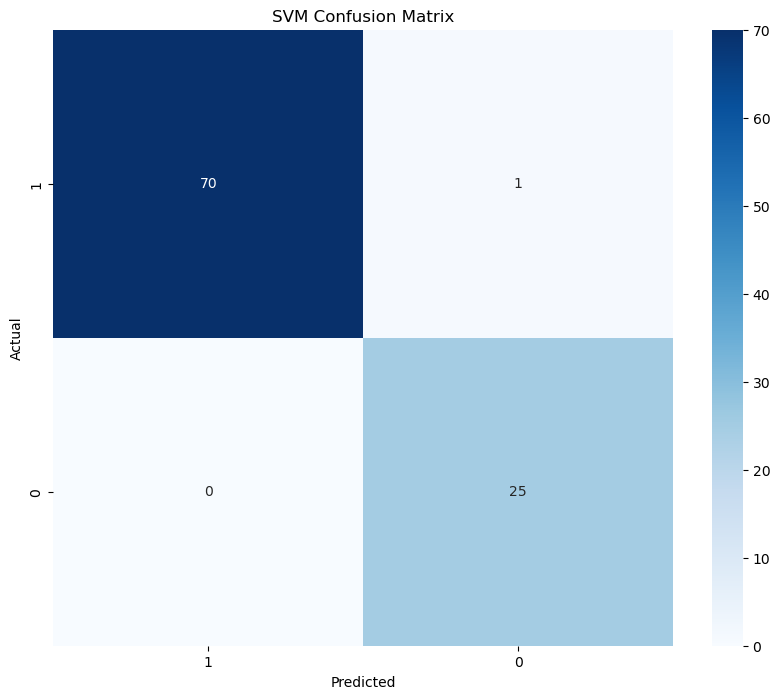

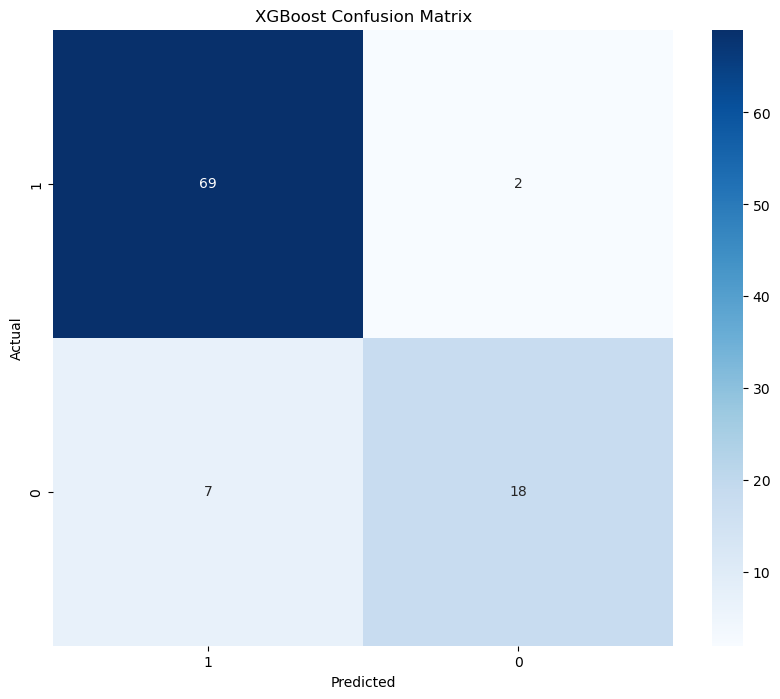

In [4]:
import pandas as pd
import re
import jieba
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier
from gensim.models import Word2Vec
import os
import seaborn as sns
import matplotlib.pyplot as plt

# 安装插件和库
# pip install pandas numpy scikit-learn xgboost gensim openpyxl jieba seaborn matplotlib

# 输入文件路径
file_path = "data/测试数据.xlsx"

# 读取数据
data = pd.read_excel(file_path)

# 数据预处理
# 加载停用词
with open('data/stopwords-master/Stopwords.txt', 'r', encoding='utf-8') as f:
    stopwords = set([line.strip() for line in f.readlines()])

# 预处理函数
def preprocess_text(s):
    s = re.sub(r'[^\w\s]', '', s)  # 去除标点符号
    s = re.sub(r'\b\d+\b', 'NUM', s)  # 将数字替换为NUM
    words = jieba.cut(s)
    words = [word for word in words if word not in stopwords]  # 去除停用词
    return ' '.join(words)

# 应用预处理
data['processed_content'] = data['news_content'].apply(preprocess_text)

# 划分训练集和测试集
train_data, test_data = train_test_split(data, test_size=0.15, random_state=42)

# 特征工程
# TF-IDF特征
tv = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tv.fit_transform(train_data['processed_content'])
X_test_tfidf = tv.transform(test_data['processed_content'])

# Word2Vec特征
sentences = [text.split() for text in train_data['processed_content']]
word2vec_model = Word2Vec(sentences, vector_size=100, window=5, min_count=5, workers=4)

def text_to_vector(text):
    words = text.split()
    vectors = [word2vec_model.wv[word] for word in words if word in word2vec_model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(word2vec_model.vector_size)

X_train_w2v = np.array([text_to_vector(text) for text in train_data['processed_content']])
X_test_w2v = np.array([text_to_vector(text) for text in test_data['processed_content']])

# 将TF-IDF和Word2Vec特征合并
X_train = np.hstack((X_train_tfidf.toarray(), X_train_w2v))
X_test = np.hstack((X_test_tfidf.toarray(), X_test_w2v))

# 模型训练与优化
# 使用SVM作为基线模型
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train, train_data['keyword'])

# 使用GridSearchCV进行超参数优化
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, train_data['keyword'])
best_svm_model = grid_search.best_estimator_

# 使用XGBoost进行集成学习
xgb_model = XGBClassifier()
xgb_model.fit(X_train, train_data['keyword'])

# 模型评估
svm_pred = best_svm_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

print("SVM分类报告：")
print(classification_report(test_data['keyword'], svm_pred, labels=train_data['keyword'].unique()))

print("XGBoost分类报告：")
print(classification_report(test_data['keyword'], xgb_pred, labels=train_data['keyword'].unique()))

# 保存预测结果
test_data_with_predictions = pd.DataFrame({
    'news_content': test_data['news_content'],
    'keyword': test_data['keyword'],
    'predicted_keyword_svm': svm_pred,
    'predicted_keyword_xgb': xgb_pred
})

# 按预测的类别分组并保存到不同的xlsx文件中
output_dir = "data/预测结果"
os.makedirs(output_dir, exist_ok=True)

for keyword in test_data_with_predictions['predicted_keyword_svm'].unique():
    subset = test_data_with_predictions[test_data_with_predictions['predicted_keyword_svm'] == keyword]
    file_name = os.path.join(output_dir, f"话题检测_{keyword}_svm.xlsx")
    subset.to_excel(file_name, index=False)
    print(f"已将类别为'{keyword}'的数据保存到文件 {file_name}")

for keyword in test_data_with_predictions['predicted_keyword_xgb'].unique():
    subset = test_data_with_predictions[test_data_with_predictions['predicted_keyword_xgb'] == keyword]
    file_name = os.path.join(output_dir, f"话题检测_{keyword}_xgb.xlsx")
    subset.to_excel(file_name, index=False)
    print(f"已将类别为'{keyword}'的数据保存到文件 {file_name}")

# 生成混淆矩阵
cm_svm = confusion_matrix(test_data['keyword'], svm_pred)
cm_xgb = confusion_matrix(test_data['keyword'], xgb_pred)

# 可视化混淆矩阵 - SVM
plt.figure(figsize=(10, 8))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=train_data['keyword'].unique(), 
            yticklabels=train_data['keyword'].unique())
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

# 可视化混淆矩阵 - XGBoost
plt.figure(figsize=(10, 8))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', 
            xticklabels=train_data['keyword'].unique(), 
            yticklabels=train_data['keyword'].unique())
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost Confusion Matrix')
plt.show()
